# Clustering Astronomical Objects with SDSS Data
## Can a computer find groups of stars, galaxies and quasars without being told what they are?

In the decision-tree notebook, we used **supervised machine learning**. We gave the computer both:

- measurements of each astronomical object, and
- the correct label: **STAR, GALAXY or QSO**.

Now we will do something different.

We will use **unsupervised machine learning**.

This time, the clustering algorithm will only see the astronomical colours. We will **hide the known class labels while it is learning**.

The question is:

> If we give the computer only the photometric colours, will it naturally find groups that correspond to real astronomical populations?

We will use **K-means clustering**.

### What you will learn

1. Load the same SDSS catalogue
2. Clean invalid photometric measurements
3. Calculate astronomical colours
4. Understand the difference between supervised and unsupervised learning
5. Scale the features
6. Use K-means clustering
7. Visualise the clusters
8. Compare the clusters with the known astronomical classes
9. Explore how changing the number of clusters changes the result

# 1. Import packages

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 2. Load the SDSS catalogue

We will use the **same file as the decision-tree notebook**:

`sdss_decision_tree.csv`

Put the CSV in the same folder as this notebook.

Unlike the previous notebook, we are not going to use the `class` column to train the machine-learning model.

In [2]:
DATA_FILE = Path("sdss_decision_tree.csv")

data = pd.read_csv(DATA_FILE)

print("Number of objects:", len(data))
print()
print("Columns:")
print(data.columns.tolist())

display(data.head())

Number of objects: 12000

Columns:
['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift', 'class']


,ra,dec,u,g,r,i,z,redshift,class
0,145.28112,-0.330472,19.36548,18.94647,19.04925,19.21883,19.35806,0.000111,STAR
1,145.28412,0.706299,20.36442,18.21354,17.38881,17.11562,17.32000,0.000178,STAR
2,145.29280,0.376335,19.31302,18.13527,17.67289,17.49996,17.44187,0.000213,STAR
3,145.26257,0.310931,24.85999,20.76403,19.18368,17.93489,17.28289,0.000066,STAR
4,145.73040,1.164938,18.32052,17.01957,16.47373,16.26664,16.14915,0.000286,STAR


# 3. Clean the photometry

Some astronomical catalogues contain special placeholder values when a reliable measurement was not available.

These can sometimes be extremely large negative numbers.

Those values are **not real astronomical magnitudes** and would strongly affect our clustering.

For this exercise, we will keep objects with sensible measurements between magnitude 10 and 30 in all five SDSS filters.

In [3]:
before = len(data)

# Keep only objects where ALL five magnitudes
# are between 10 and 30
good_data = (
    (data["u"].between(10, 30)) &
    (data["g"].between(10, 30)) &
    (data["r"].between(10, 30)) &
    (data["i"].between(10, 30)) &
    (data["z"].between(10, 30))
)

data = data[good_data].copy()

after = len(data)

print("Objects before cleaning:", before)
print("Objects after cleaning:", after)
print("Objects removed:", before - after)

Objects before cleaning: 12000
Objects after cleaning: 11986
Objects removed: 14


# 4. Calculate astronomical colours

Rather than clustering using the raw magnitudes, we will use **colours**.

A colour is the difference between two magnitudes.

For example:

`u - g = u magnitude - g magnitude`

Colours tell us about the **shape of an object's spectrum**. Different types of astronomical objects can therefore occupy different regions of colour space.

In [4]:
data["u-g"] = data["u"] - data["g"]
data["g-r"] = data["g"] - data["r"]
data["r-i"] = data["r"] - data["i"]
data["i-z"] = data["i"] - data["z"]

display(
    data[
        ["u-g", "g-r", "r-i", "i-z", "class"]
    ].head()
)

,u-g,g-r,r-i,i-z,class
0,0.41901,-0.10278,-0.16958,-0.13923,STAR
1,2.15088,0.82473,0.27319,-0.20438,STAR
2,1.17775,0.46238,0.17293,0.05809,STAR
3,4.09596,1.58035,1.24879,0.65200,STAR
4,1.30095,0.54584,0.20709,0.11749,STAR


# 5. Look at the colour space

Before asking a machine-learning algorithm to find patterns, let's look at two of the colours ourselves.

Importantly, we will **not colour the points by STAR, GALAXY or QSO yet**.

Imagine that we do not know what these objects are.

Can you see any structure or groups?

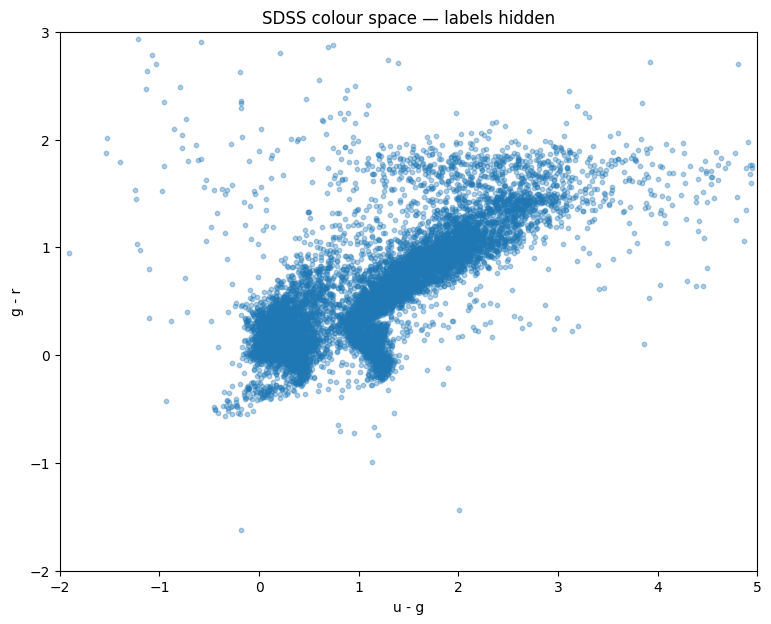

In [5]:
plt.figure(figsize=(9, 7))

plt.scatter(
    data["u-g"],
    data["g-r"],
    s=10,
    alpha=0.35
)

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.title("SDSS colour space — labels hidden")
plt.xlim(-2, 5)
plt.ylim(-2, 3)

plt.show()

# 6. Choose the features

We will give K-means four colours:

- `u-g`
- `g-r`
- `r-i`
- `i-z`

Notice what is **missing**:

`class`

We are deliberately not giving K-means the answers.

This is the major difference from our decision tree.

In [53]:
#features = ["u-g", "g-r"] #, "r-i", "i-z"]
features = ["u", "g", "r", "i", "z", "redshift"]

X = data[features]

display(X.head())

,u,g,r,i,z,redshift
0,19.36548,18.94647,19.04925,19.21883,19.35806,0.000111
1,20.36442,18.21354,17.38881,17.11562,17.32000,0.000178
2,19.31302,18.13527,17.67289,17.49996,17.44187,0.000213
3,24.85999,20.76403,19.18368,17.93489,17.28289,0.000066
4,18.32052,17.01957,16.47373,16.26664,16.14915,0.000286


# 7. Scale the data

K-means works using **distances** between points.

That means the numerical scale of each feature matters.

To make the colours comparable, we use a `StandardScaler`.

This transforms each feature so that it is centred around zero and has a similar scale.

We are not changing which objects are similar to one another — we are making sure one feature does not dominate simply because it has a larger numerical range.

In [54]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.28542192  0.20192617  0.72153015  1.1276132   1.3481248  -0.64596729]
 [ 0.31994944 -0.30320532 -0.47387971 -0.44884189 -0.13858667 -0.64586618]
 [-0.3172134  -0.35714859 -0.2693604  -0.16076093 -0.04968569 -0.64581372]
 [ 3.04432658  1.45457895  0.8183111   0.16523962 -0.16565744 -0.64603544]
 [-0.91868203 -1.12608316 -1.13267837 -1.08519244 -0.99269112 -0.64570452]]


# 8. Build a K-means clustering model

K-means tries to divide our data into groups called **clusters**.

We need to tell it how many clusters to look for.

We already know our catalogue contains three labelled populations:

- stars
- galaxies
- quasars

So, as a first experiment, we will ask for:

`n_clusters = 3`

However, K-means does **not** know that these are stars, galaxies and quasars.

It simply tries to find three groups of objects that are close together in our four-dimensional colour space.

In [55]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

data["cluster"] = clusters

data[["u-g", "g-r", "r-i", "i-z", "cluster"]].head()

,u-g,g-r,r-i,i-z,cluster
0,0.41901,-0.10278,-0.16958,-0.13923,0
1,2.15088,0.82473,0.27319,-0.20438,1
2,1.17775,0.46238,0.17293,0.05809,1
3,4.09596,1.58035,1.24879,0.65200,2
4,1.30095,0.54584,0.20709,0.11749,1


# 9. What did K-means create?

K-means has assigned every object a cluster number:

- Cluster 0
- Cluster 1
- Cluster 2

These numbers have **no astronomical meaning by themselves**.

Cluster 0 does not automatically mean STAR, and Cluster 1 does not automatically mean GALAXY.

They are simply names for the groups found by the algorithm.

In [56]:
print(data["cluster"].value_counts().sort_index())

cluster
0    4206
1    6434
2    1346
Name: count, dtype: int64


# 10. Plot the clusters

Now let's return to our `u-g` versus `g-r` colour-colour diagram.

This time, colour each point according to the **cluster assigned by K-means**.

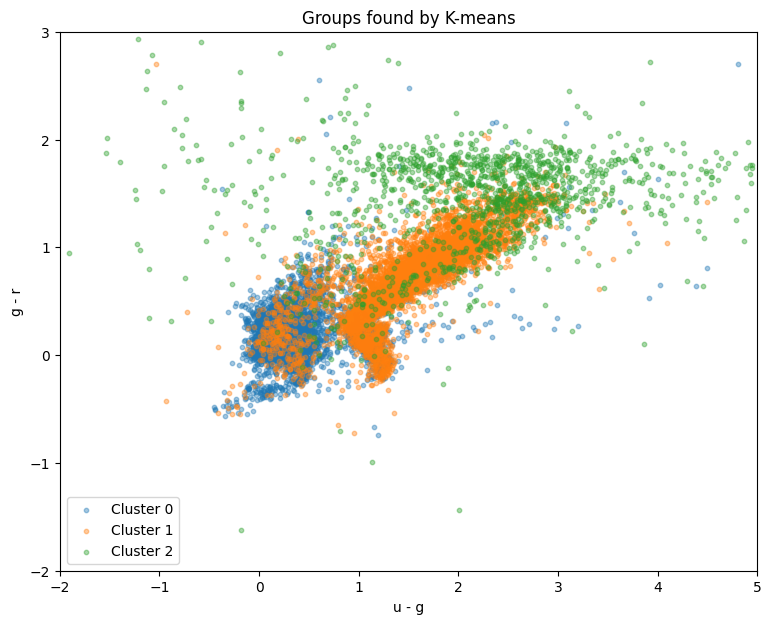

In [57]:
plt.figure(figsize=(9, 7))

for cluster in sorted(data["cluster"].unique()):

    subset = data[data["cluster"] == cluster]

    plt.scatter(
        subset["u-g"],
        subset["g-r"],
        s=10,
        alpha=0.4,
        label=f"Cluster {cluster}"
    )

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.title("Groups found by K-means")
plt.xlim(-2, 5)
plt.ylim(-2, 3)
plt.legend()

plt.show()

# 11. Now reveal the real astronomical classes

Up to this point, K-means has **never used the `class` column**.

But because our SDSS catalogue came from spectroscopic observations, we actually know whether each object was classified as a STAR, GALAXY or QSO.

We can now reveal those labels and compare them with the groups K-means discovered.

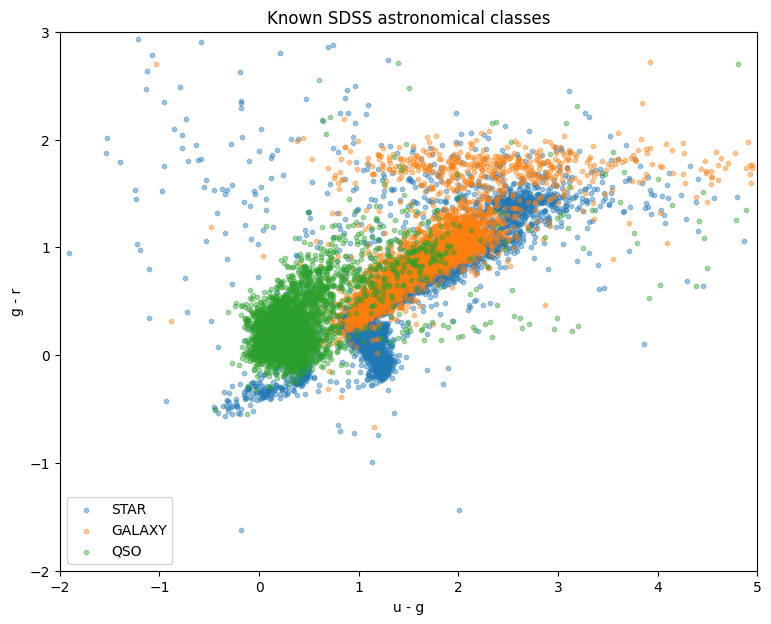

In [58]:
plt.figure(figsize=(9, 7))

for object_class in ["STAR", "GALAXY", "QSO"]:

    subset = data[data["class"] == object_class]

    plt.scatter(
        subset["u-g"],
        subset["g-r"],
        s=10,
        alpha=0.4,
        label=object_class
    )

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.title("Known SDSS astronomical classes")
plt.xlim(-2, 5)
plt.ylim(-2, 3)
plt.legend()

plt.show()

# 12. Compare clusters with the known classes

A useful way to compare the two is with a table.

The rows are the clusters found by K-means.

The columns are the known spectroscopic classes.

Remember: these labels were **not used to create the clusters**.

In [12]:
comparison = pd.crosstab(
    data["cluster"],
    data["class"]
)

comparison

class,GALAXY,QSO,STAR
cluster,,,
0,3167,294,1154
1,826,3696,2633
2,2,3,211


We can also convert the counts into percentages.

This makes it easier to ask questions such as:

- Is one cluster mostly stars?
- Is one mostly galaxies?
- Where do quasars appear?
- Are any clusters strongly mixed?

In [20]:
comparison_percent = pd.crosstab(
    data["cluster"],
    data["class"],
    normalize="index"
) * 100

comparison_percent.round(1)

class,GALAXY,QSO,STAR
cluster,,,
0,65.9,6.1,28.0
1,12.4,50.8,36.8


# 13. Why don't the clusters perfectly match the classes?

It would be tempting to expect:

- one cluster = stars
- one cluster = galaxies
- one cluster = quasars

But K-means has no knowledge of those categories.

It only knows the distances between points in colour space.

Real astronomical populations can overlap in colour. Objects within the same broad class can also have very different physical properties.

This highlights an important idea:

> A cluster is a statistical grouping in the measurements we chose. It is not automatically a physical astronomical class.

Interpreting clusters requires us to bring the **astronomy back into the analysis**.

# 14. How does K-means work?

K-means repeatedly performs a simple process.

### Step 1 — choose centres

It begins with `K` points called **cluster centres** or **centroids**.

### Step 2 — assign objects

Each astronomical object is assigned to the nearest centroid.

### Step 3 — move the centres

The centroid is moved to the average position of all the objects assigned to it.

### Step 4 — repeat

The assignments and centroids are updated repeatedly until they stop changing very much.

The result is a set of clusters where objects within each group are relatively close together in the feature space.

In our case, that feature space has four dimensions:

`u-g`, `g-r`, `r-i`, and `i-z`.

# 15. What if we choose a different number of clusters?

There is nothing magical about choosing three clusters.

Let's try several values of **K**.

We can use the **silhouette score** as one simple measure of how well separated the resulting clusters are.

A larger silhouette score generally indicates more clearly separated clusters.

In [21]:
k_values = range(2, 9)

scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    scores.append(score)

    print(f"K = {k}: silhouette score = {score:.3f}")

K = 2: silhouette score = 0.483
K = 3: silhouette score = 0.498
K = 4: silhouette score = 0.501
K = 5: silhouette score = 0.505
K = 6: silhouette score = 0.434
K = 7: silhouette score = 0.367
K = 8: silhouette score = 0.369


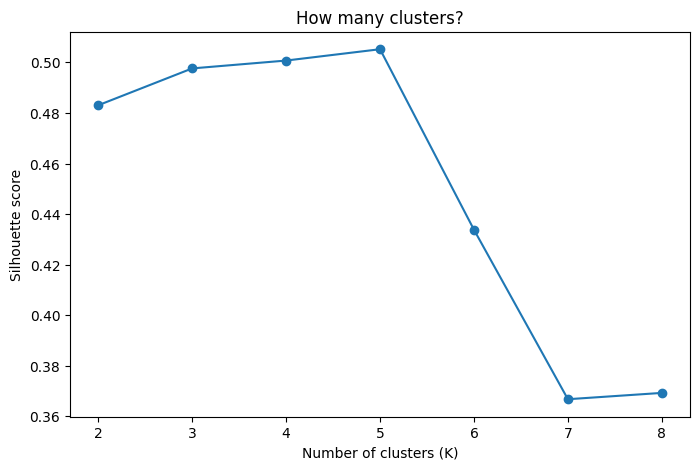

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    scores,
    marker="o"
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("How many clusters?")
plt.xticks(list(k_values))

plt.show()

# Your turn

## Exercise 1 — change K

Try:

```python
n_clusters=2
```

then:

```python
n_clusters=4
n_clusters=5
n_clusters=6
```

Plot the resulting clusters each time.

Do any of these reveal interesting substructure?

---

## Exercise 2 — use only two colours

Try clustering with:

```python
features = ["u-g", "g-r"]
```

How does the result change?

---

## Exercise 3 — use the raw magnitudes

Instead of colours, try:

```python
features = ["u", "g", "r", "i", "z"]
```

Scale the data again and rerun K-means.

Do the clusters correspond to the same astronomical populations?

What information are the raw magnitudes introducing that colours do not?

---

## Exercise 4 — investigate one cluster

Choose one cluster and inspect the objects inside it:

```python
data[data["cluster"] == 0]
```

What fraction are stars, galaxies and quasars?

Look at their colours. What makes this group distinctive?

---

## Exercise 5 — forget that we know there are three classes

Imagine this were a completely new astronomical survey and nobody had told you how many populations existed.

Based only on the colour-space plots and silhouette scores:

> How many clusters would you choose?

Would your answer necessarily be three?

# Take-home idea

Clustering is an example of **unsupervised machine learning**.

Unlike our decision tree, K-means was never shown which objects were stars, galaxies or quasars.

It was only given astronomical measurements and asked to find structure.

We could then compare those statistically discovered groups with known astronomical classifications.

This is one reason unsupervised learning can be useful in astronomy: it can help us explore large datasets without first deciding exactly what categories we expect to find.

But the algorithm does not tell us what a cluster **means**.

That part still requires astronomy.